# Ecommerce Return Classification

### Defining Business Problem:
> Business is getting too many returns and we have data of Orders from cart amount to return risk or return success

### Identifying Target Variable
> return_risk_label

#### Why:
> Need to minimize risk for returns on Orders.

### Basic Explaining Of Business pronlem
> An Ecommerce Business company  wants to predict which orders are likely to be returned, So it can be Identify high risk order and reduce Product Returns.

### How ML can address the problem?
> In this problem we can use Classification Models that can help us to identify either received order has high return risk or not.

# Data Understanding &amp; EDA

### Dataset structure and data types

In [11]:
import pandas as pd
import numpy as np

In [12]:
df = pd.read_csv("../raw_data/ecommerce_return_classification.csv")

In [13]:
df.head()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,172.17,0.233,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,213.55,0.235,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,152.68,0.133,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2993 entries, 0 to 2992
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cart_value_usd         2993 non-null   float64
 1   past_return_rate       2993 non-null   float64
 2   size_bracketing_flag   2993 non-null   int64  
 3   delivery_days_taken    2993 non-null   int64  
 4   discount_pct_applied   2993 non-null   int64  
 5   product_category       2993 non-null   str    
 6   fit_review_sentiment   2993 non-null   str    
 7   newsletter_subscriber  2993 non-null   int64  
 8   browser_used           2993 non-null   str    
 9   checkout_device        2993 non-null   str    
 10  packaging_color        2993 non-null   str    
 11  loyalty_card_color     2993 non-null   str    
 12  return_risk_label      2993 non-null   int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 481.6 KB


### Descriptive statistics

In [15]:
df.describe()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,newsletter_subscriber,return_risk_label
count,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000
mean,239.630274,0.284024,0.354160,5.974273,23.879051,0.503508,0.645506
std,121.454170,0.159998,0.478338,3.188330,17.263143,0.500071,0.478440
min,0.000000,0.005000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,135.370000,0.157000,0.000000,3.000000,10.000000,0.000000,0.000000
50%,238.690000,0.265000,0.000000,6.000000,20.000000,1.000000,1.000000
75%,343.680000,0.386000,1.000000,9.000000,40.000000,1.000000,1.000000
max,449.860000,0.884000,1.000000,11.000000,50.000000,1.000000,1.000000


### Missing values and duplicates

In [16]:
df.isnull().sum()

cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

### Helping and Reuseable Code

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
all_num_cols = df.describe().columns
all_cat_cols = df.describe(include="O").columns

def showBoxPlot(data, col):
    plt.title(f"Box plot for Checking Outliers for: {col}")
    sns.boxplot(x=data[col])
    plt.xlabel(col)
    plt.show()

/var/folders/41/49dnj5213l1f6btjl3b5rdlh0000gn/T/ipykernel_5189/2311315400.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  all_cat_cols = df.describe(include="O").columns


### Outlier analysis

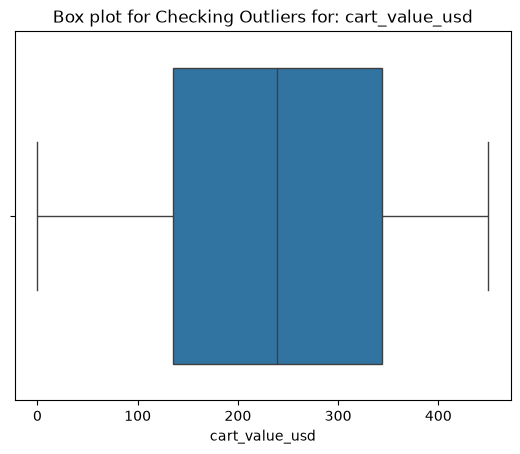

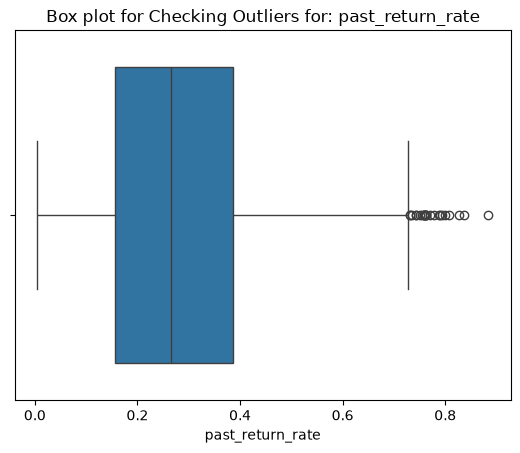

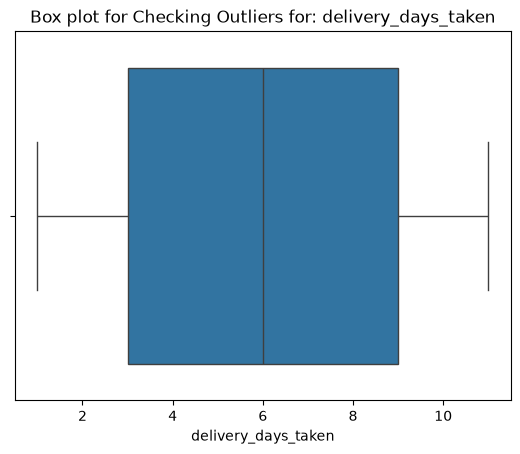

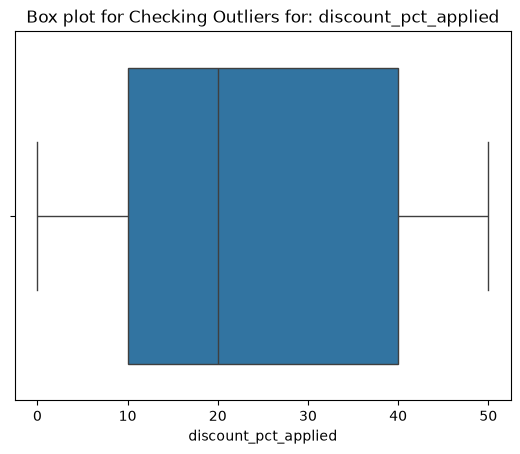

In [31]:
for col in all_num_cols.drop(["return_risk_label", "newsletter_subscriber", "size_bracketing_flag"]):
    showBoxPlot(df, col)

We Can Clearly see Outliers in Past Return Rate So need to remove Outlier in data

In [36]:
q1 = df["past_return_rate"].quantile(0.25)
q3 = df["past_return_rate"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

print("Lower Bound: ", lower_bound)
print("Upper Bound: ", upper_bound)

lower_bound = lower_bound if lower_bound >= 0  else 0

print(lower_bound)

Lower Bound:  -0.18650000000000003
Upper Bound:  0.7295
0


In [41]:
df = df[(df["past_return_rate"] > lower_bound) & (df["past_return_rate"] < upper_bound)]